# Chapter 15 — Capstone: a localisation stack for the mower

Companion notebook to **Chapter 15**: the evaluation metrics (ATE with the right alignment, RPE over a distance, NEES),
the χ² gate, and the full stack on the first 25 s of the drive, with its health reports. `examples/ch15_stack.py`
runs the complete evaluation.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2
from vslam import evaluation, lie
from ch13_vio import setup
from ch14_fusion import sensors
from ch15_stack import run_stack, summary

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The alignment decides the ATE (Definition 15.1)

A trajectory with a heading drift: the unaligned ATE sees it, the 4-DoF and SE(3) alignments hide it.

In [2]:
t = np.linspace(0, 60, 600)
gt = np.column_stack([t, 2 * np.sin(t / 5), np.zeros_like(t)])
drift = np.radians(0.05) * t                       # heading drift, 0.05 deg/s
est = np.column_stack([gt[:, 0] * np.cos(drift) - gt[:, 1] * np.sin(drift),
                       gt[:, 0] * np.sin(drift) + gt[:, 1] * np.cos(drift), gt[:, 2]])
for a in ["none", "4dof", "se3"]:
    print(f"ATE, alignment {a:5s}: {100 * np.sqrt(np.mean(evaluation.ate(est, gt, a) ** 2)):6.1f} cm")

ATE, alignment none :  140.7 cm
ATE, alignment 4dof :   23.8 cm
ATE, alignment se3  :   23.8 cm


## 2. NEES of a consistent and of an overconfident estimator (Proposition 15.3)

In [3]:
n, d = 300, 3
P = np.tile(np.diag([0.02, 0.02, 0.04]) ** 2, (n, 1, 1))
e = rng.normal(size=(n, d)) * np.array([0.02, 0.02, 0.04])
for name, scale in [("consistent", 1.0), ("overconfident (reports half the std)", 0.5)]:
    ne = evaluation.nees(e, P * scale ** 2)
    lo, hi = evaluation.anees_bounds(n, d)
    print(f"{name:38s} ANEES {ne.mean():5.2f}  (95 % interval [{lo:.2f}, {hi:.2f}]),"
          f" above chi2(0.99): {100 * np.mean(ne > chi2.ppf(0.99, d)):.1f} %")

consistent                             ANEES  2.85  (95 % interval [2.73, 3.28]), above chi2(0.99): 1.3 %
overconfident (reports half the std)   ANEES 11.39  (95 % interval [2.73, 3.28]), above chi2(0.99): 36.0 %


## 3. The χ² gate (Proposition 15.4)

In [4]:
S = np.diag([0.02, 0.02, 0.04]) ** 2
for r in [np.array([0.01, -0.02, 0.03]), np.array([0.3, 0.0, 0.0])]:
    q, ok = evaluation.nis_gate(r, S)
    print(f"innovation {r}: NIS {q:7.1f} -> {'accepted' if ok else 'rejected'} (threshold {chi2.ppf(0.999, 3):.1f})")

innovation [ 0.01 -0.02  0.03]: NIS     1.8 -> accepted (threshold 16.3)
innovation [0.3 0.  0. ]: NIS   225.0 -> rejected (threshold 16.3)


## 4. The full stack on 25 s of the drive, with the camera blind under the tree

From 5.5 s to 9.5 s the camera sees nothing while the mower passes under the young tree, where the RTK solution is
float and suffers multipath.

GNSS: 79 accepted, 13 rejected; ANEES 1.99; healthy throughout: True
  t =  7.00 s: fix rejected, NIS 190.3
  t = 20.00 s: fix rejected, NIS 753.3
  t = 20.25 s: fix rejected, NIS 206.3
  t = 20.50 s: fix rejected, NIS 530.5
  t = 22.00 s: fix rejected, NIS 696.9
  t = 22.50 s: fix rejected, NIS 327.3
  t = 23.00 s: fix rejected, NIS 19.6
  t = 23.25 s: fix rejected, NIS 17.0
  t = 23.50 s: fix rejected, NIS 25.3
  t = 23.75 s: fix rejected, NIS 22.2
  t = 24.00 s: fix rejected, NIS 16.9
  t = 24.25 s: fix rejected, NIS 20.0
  t = 24.50 s: fix rejected, NIS 16.5


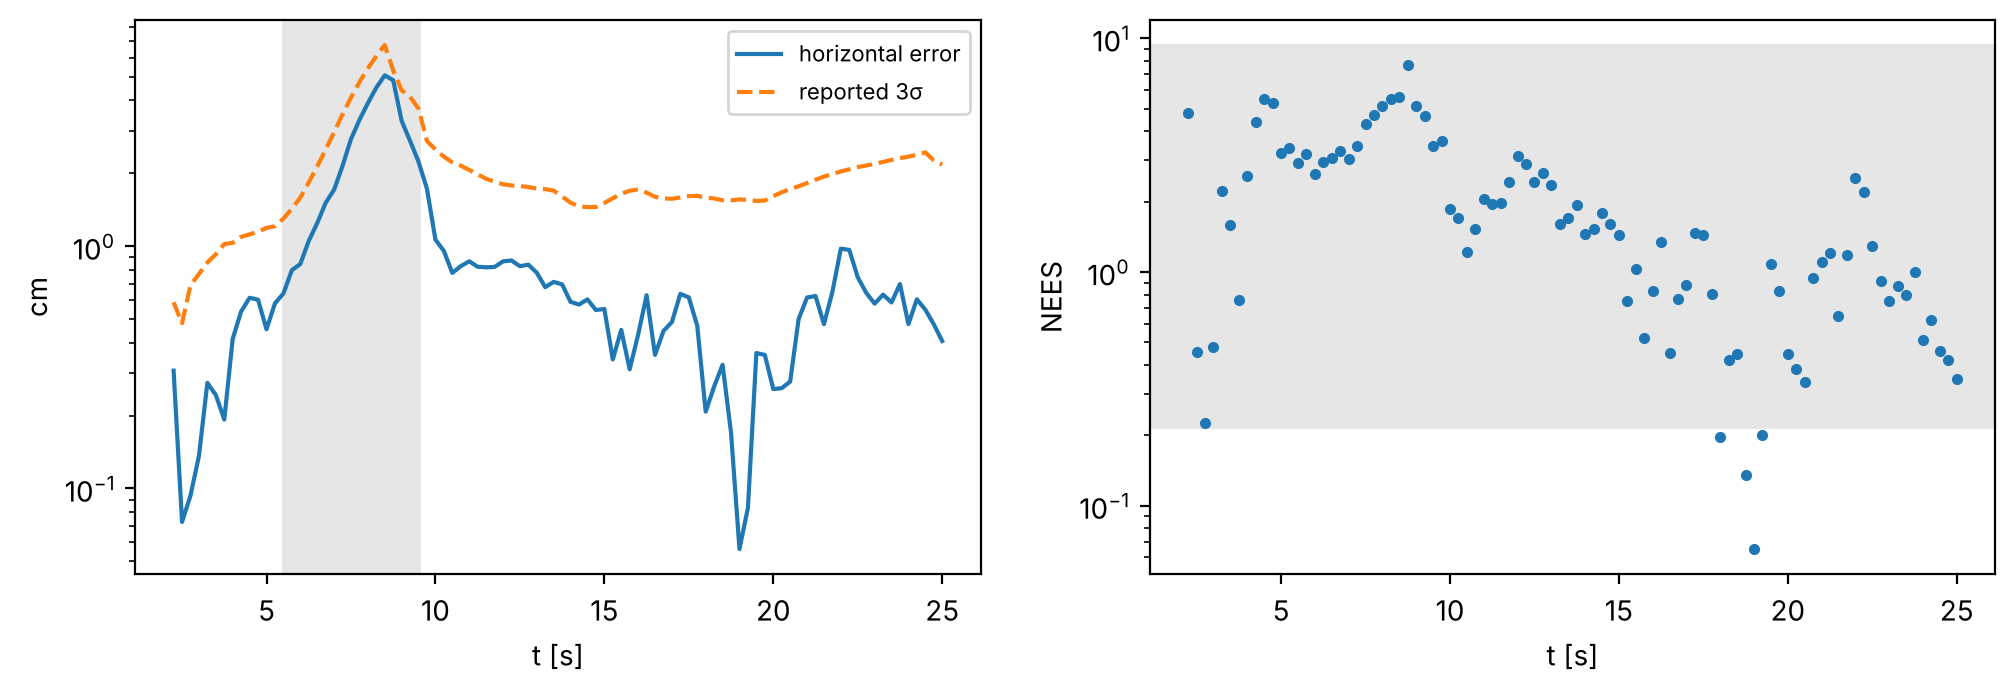

In [5]:
m, Pm, data, S_, Tbc, ts, frames = setup()
sens = sensors(m)
st = run_stack(m, Pm, data, S_, Tbc, ts, frames, sens, blind=(5.5, 9.5), t_end=25.0)
t, e, ne, sh = summary(m, st)
eh = np.linalg.norm(e[:, :2], axis=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].semilogy(t, 100 * eh, label="horizontal error"); ax[0].semilogy(t, 300 * sh, "--", label="reported 3σ")
ax[0].axvspan(5.5, 9.5, color="0.9"); ax[0].set_xlabel("t [s]"); ax[0].set_ylabel("cm"); ax[0].legend(fontsize=8)
ax[1].semilogy(t, ne, "."); ax[1].axhspan(*chi2.ppf([0.025, 0.975], 3), color="0.9"); ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("NEES")
dec = [r.gnss for r in st.reports]
print(f"GNSS: {dec.count('accepted')} accepted, {dec.count('rejected')} rejected; ANEES {ne.mean():.2f}; "
      f"healthy throughout: {all(r.healthy for r in st.reports)}")
for r in st.reports:
    if r.gnss == "rejected":
        print(f"  t = {r.t:5.2f} s: fix rejected, NIS {r.nis:.1f}")

## Exercises

1. Lower the alarm threshold of the stack (`sigma_alarm`) to 1 cm. When does the health flag drop, and why?
2. Run the stack without the gate (`gate=None`) and with least squares on the GNSS factor (`gnss_kernel=None`): how
   much does the multipath now hurt?
3. Inflate the covariance (`inflate=2`) and look at the NEES and at the gate's decisions.